# Matplotlib solutions: Matplotlib

Worked solutions to the exercises. Other correct answers are possible; what matters is that the result is right and the code is readable.

## Exercise 1

Load `../../datasets/raw/daily_sales.csv` and plot total units sold per week across all shops as a line chart, with a title and axis labels.

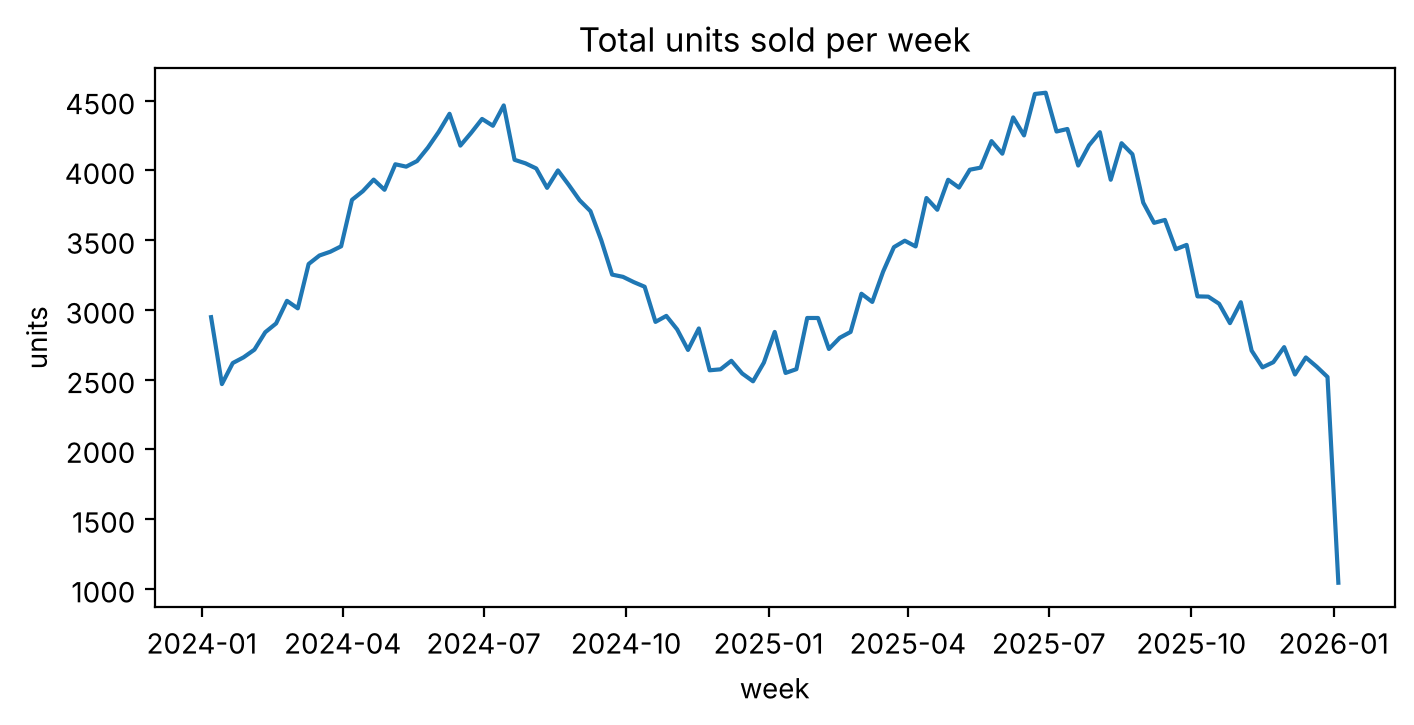

In [1]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
RAW = "../../datasets/raw/"
sales = pd.read_csv(RAW + "daily_sales.csv", parse_dates=["date"])
weekly = sales.set_index("date")["units"].resample("W").sum()
fig, ax = plt.subplots(figsize=(8, 3.5))
ax.plot(weekly.index, weekly.values)
ax.set_title("Total units sold per week")
ax.set_xlabel("week"); ax.set_ylabel("units")
plt.show()

## Exercise 2

Make a horizontal bar chart of the number of patients per site (from `patients.csv`), sorted from largest to smallest, with the largest bar at the top.

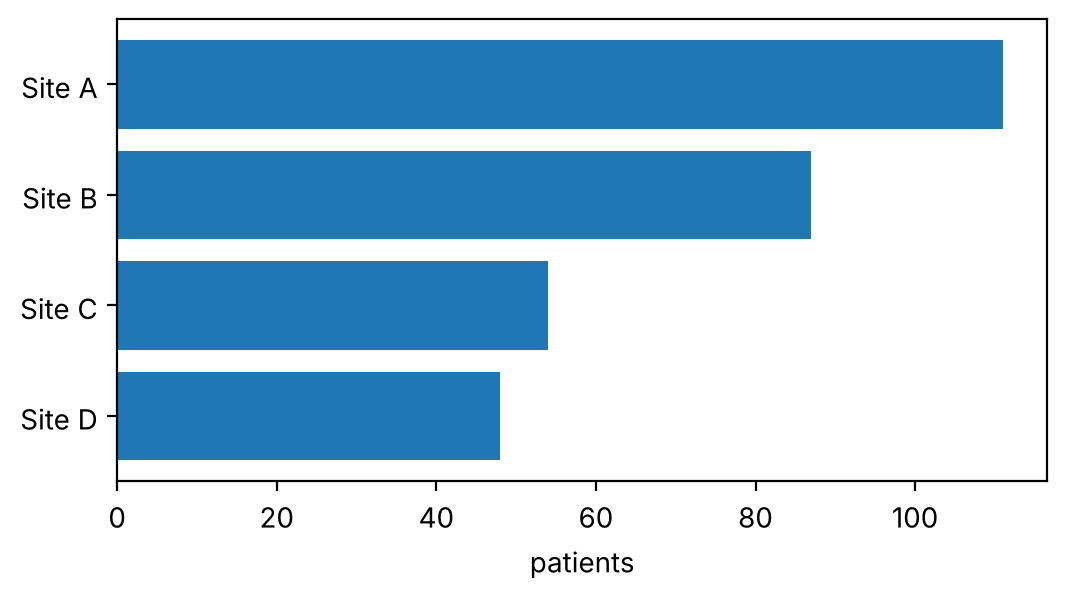

In [2]:
patients = pd.read_csv(RAW + "patients.csv")
c = patients["site"].value_counts().sort_values()
fig, ax = plt.subplots(figsize=(6, 3))
ax.barh(c.index, c.values)
ax.set_xlabel("patients")
plt.show()

## Exercise 3

Draw a histogram of haemoglobin from `lab_results.csv` with 25 bins, and add a dashed vertical line at 12 g/dL labelled 'anaemia cut-off'.

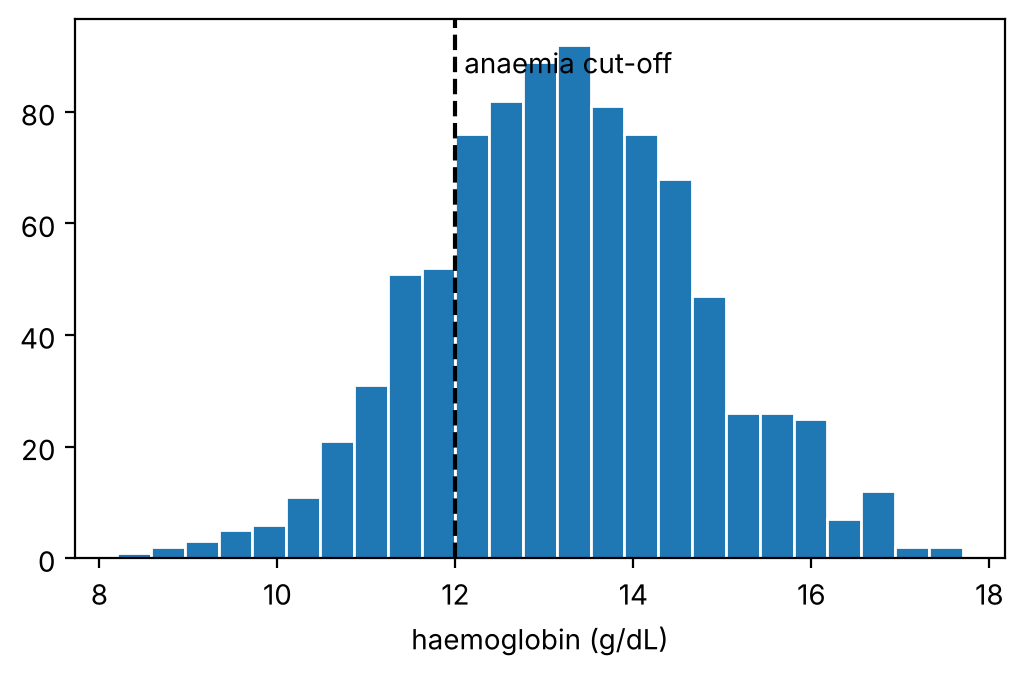

In [3]:
labs = pd.read_csv(RAW + "lab_results.csv")
fig, ax = plt.subplots(figsize=(6, 3.5))
ax.hist(labs["haemoglobin_g_dl"], bins=25, edgecolor="white")
ax.axvline(12, linestyle="--", color="black")
ax.text(12.1, ax.get_ylim()[1] * 0.9, "anaemia cut-off")
ax.set_xlabel("haemoglobin (g/dL)")
plt.show()

## Exercise 4

Make a scatter plot of systolic against diastolic BP, coloured by glucose with the `viridis` colour map, and include a colour bar.

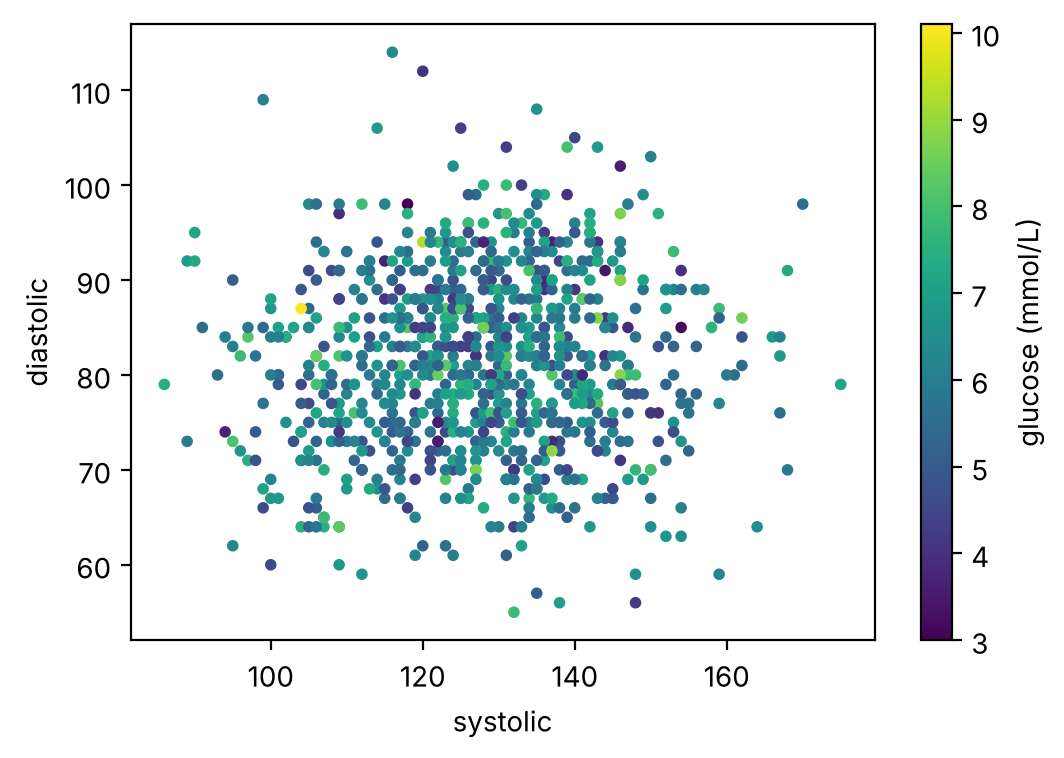

In [4]:
fig, ax = plt.subplots(figsize=(6, 4))
p = ax.scatter(labs["systolic_bp"], labs["diastolic_bp"], c=labs["glucose_mmol"], cmap="viridis", s=10)
fig.colorbar(p, ax=ax, label="glucose (mmol/L)")
ax.set_xlabel("systolic"); ax.set_ylabel("diastolic")
plt.show()

## Exercise 5

Compare the age distributions of smokers and non-smokers with a box plot.

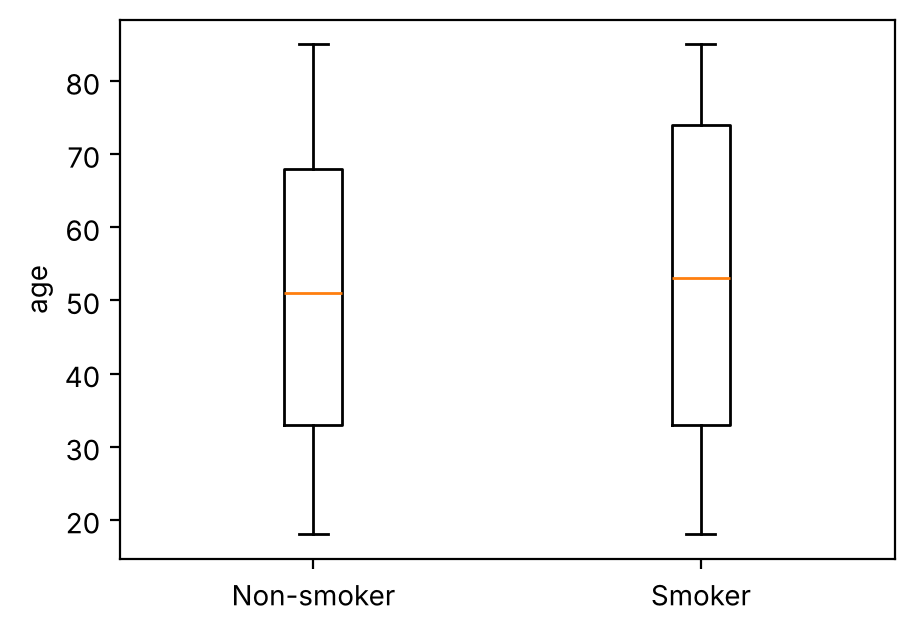

In [5]:
fig, ax = plt.subplots(figsize=(5, 3.5))
ax.boxplot([patients.loc[patients["smoker"] == s, "age"] for s in ["No", "Yes"]], tick_labels=["Non-smoker", "Smoker"])
ax.set_ylabel("age")
plt.show()

## Exercise 6

Plot mean units per day for each shop on promotion and non-promotion days as a grouped bar chart.

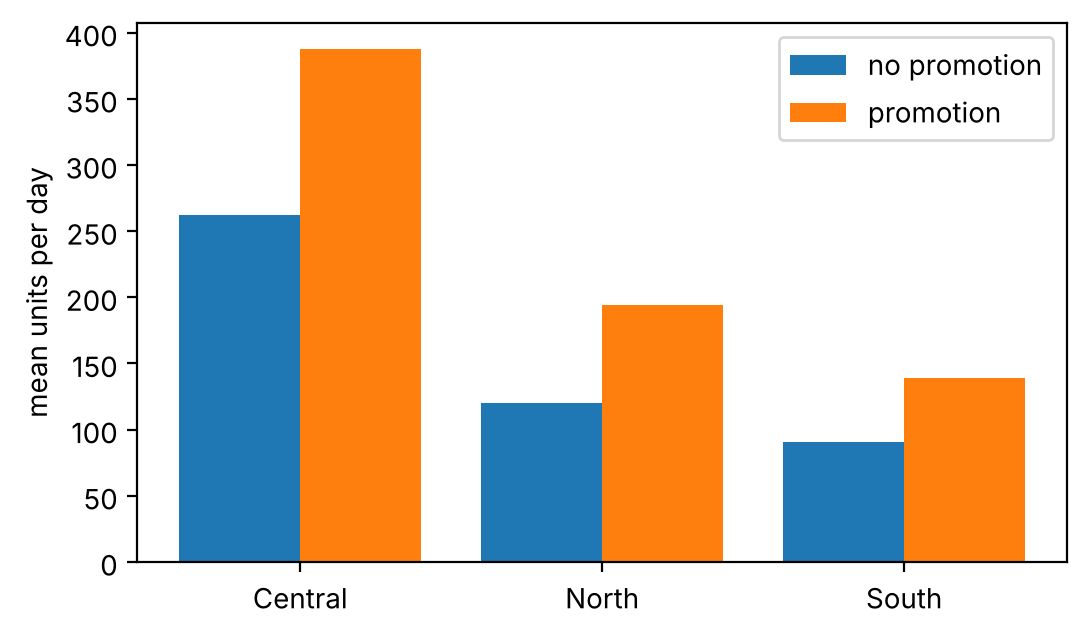

In [6]:
m = sales.groupby(["shop", "promo"])["units"].mean().unstack()
x = np.arange(len(m)); w = 0.4
fig, ax = plt.subplots(figsize=(6, 3.5))
ax.bar(x - w / 2, m[0], w, label="no promotion")
ax.bar(x + w / 2, m[1], w, label="promotion")
ax.set_xticks(x, m.index); ax.set_ylabel("mean units per day"); ax.legend()
plt.show()

## Exercise 7

Make a 1 × 3 figure with histograms of glucose, haemoglobin and systolic BP, each with its own title, and save it as `lab_panels.png` at 300 dpi. Check the file exists, then delete it.

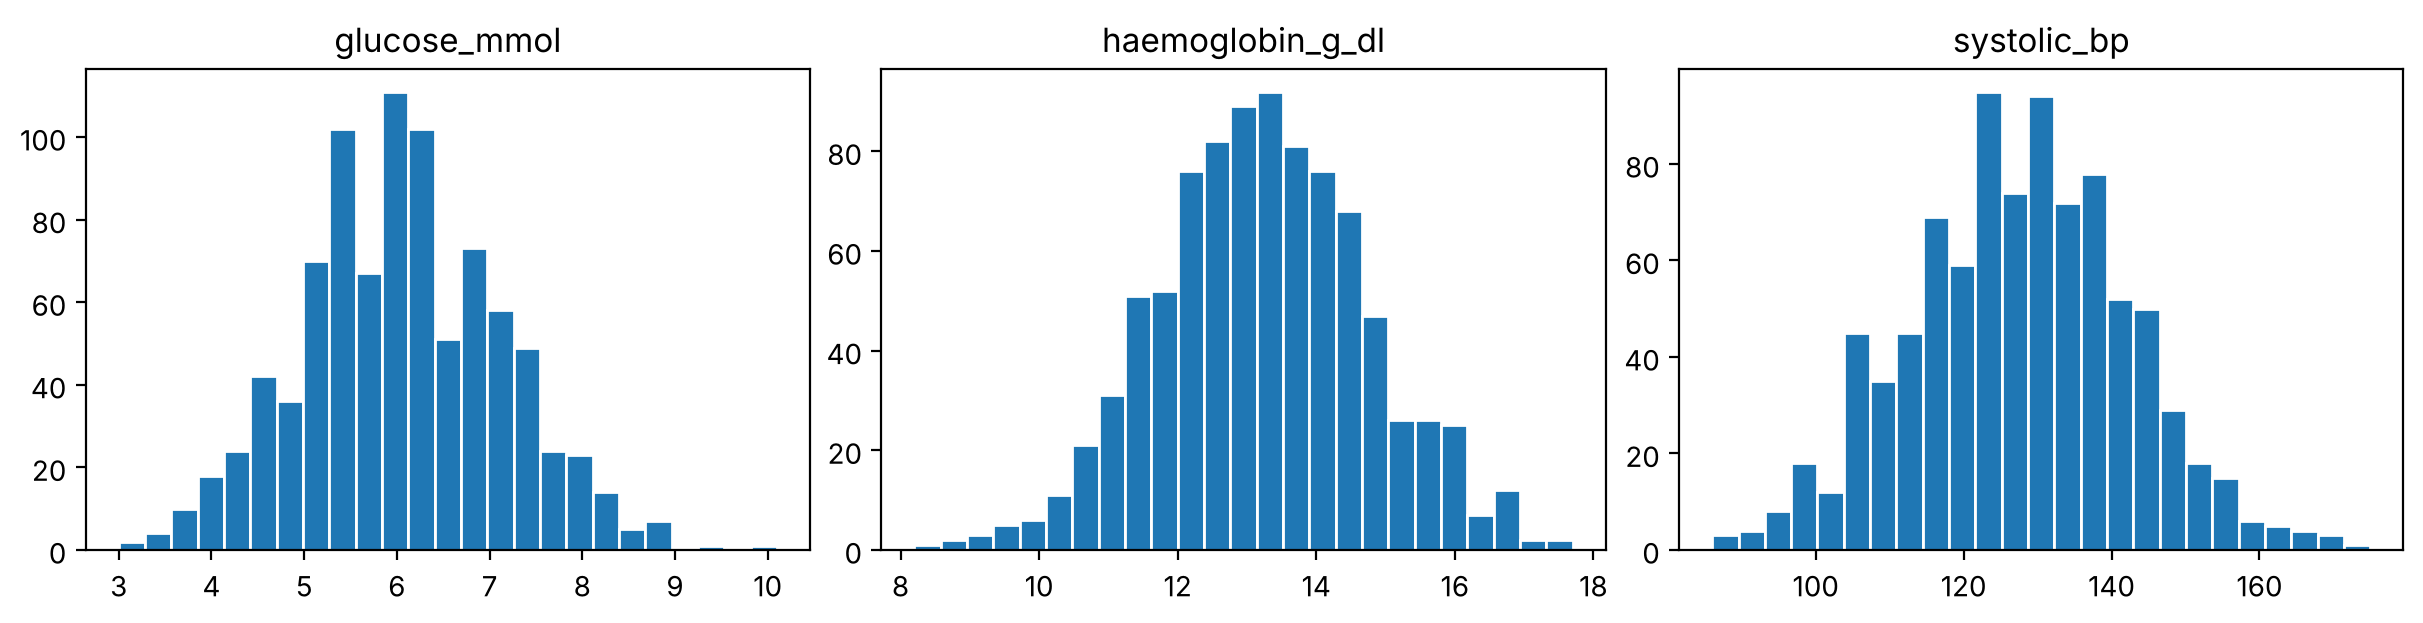

True


In [7]:
from pathlib import Path
fig, axes = plt.subplots(1, 3, figsize=(12, 3), layout="constrained")
for ax, col in zip(axes, ["glucose_mmol", "haemoglobin_g_dl", "systolic_bp"]):
    ax.hist(labs[col], bins=25, edgecolor="white"); ax.set_title(col)
fig.savefig("lab_panels.png", dpi=300, bbox_inches="tight")
plt.show()
print(Path("lab_panels.png").exists()); Path("lab_panels.png").unlink()

## Exercise 8

Draw one small panel per shop showing its monthly revenue, with shared y-axes, and a figure title.

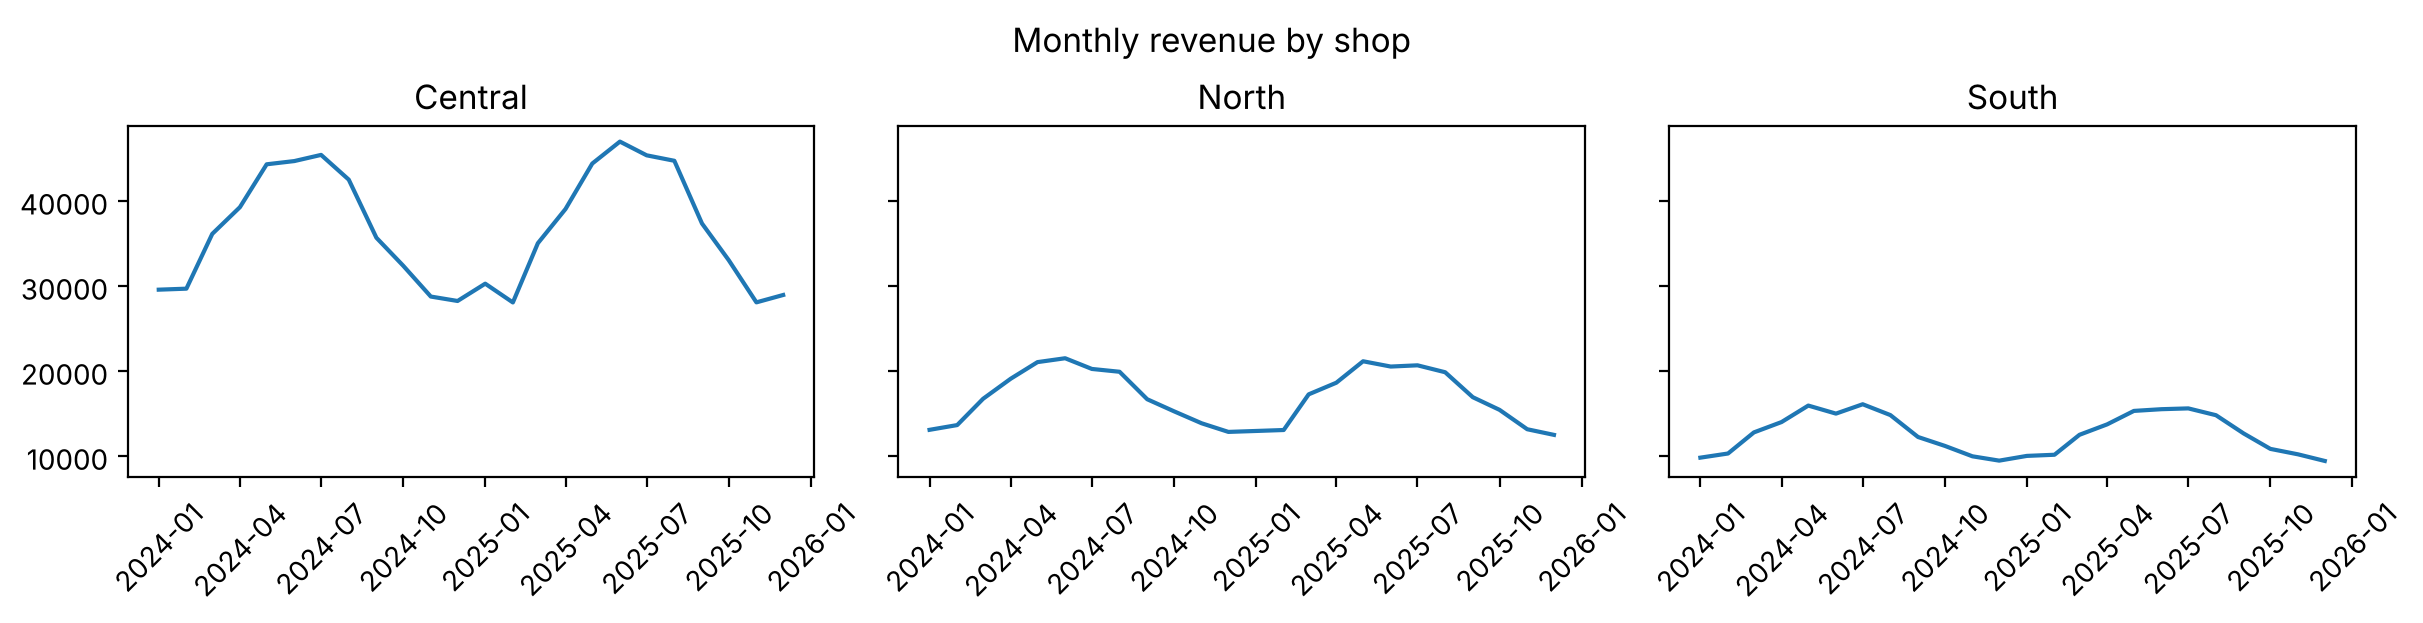

In [8]:
sales["revenue"] = sales["units"] * sales["price"]
fig, axes = plt.subplots(1, 3, figsize=(12, 3), sharey=True, layout="constrained")
for ax, (shop, g) in zip(axes, sales.groupby("shop")):
    mon = g.set_index("date")["revenue"].resample("MS").sum()
    ax.plot(mon.index, mon.values); ax.set_title(shop); ax.tick_params(axis="x", rotation=45)
fig.suptitle("Monthly revenue by shop")
plt.show()